In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix

# Fix the random seed so that sampling / plots are reproducible
np.random.seed(42)

In [2]:
X , y = fetch_openml(data_id=40996,as_frame=False,return_X_y=True,parser="auto")
X = np.array(X,dtype=np.float32)
y = np.array(y,dtype=np.float32)

print(f"shape of data : {X.shape}")
print(f"number of samples : {X.shape[0]}")
print(f"number of features : {X.shape[1]}")
print(f"number of classes : {len(np.unique(y))}")
print(f"Pixel value range : [{X.min():.0f}, {X.max():.0f}]")


shape of data : (70000, 784)
number of samples : 70000
number of features : 784
number of classes : 10
Pixel value range : [0, 255]


### 1. How is a single image represented in the dataset?

In [3]:
single_image = X[0]

print("Single image representation :  \n",single_image)

Single image representation :  
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   1.   0.
   0.  13.  73.   0.   0.   1.   4.   0.   0.   0.   0.   1.   1.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   3.   0.
  36. 136. 127.  62.  54.   0.   0.   0.   1.   3.   4.   0.   0.   3.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   6.   0.
 102. 204. 176. 134. 144. 123.  23.   0.   0.   0.   0.  12.  10.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
 155. 236. 207. 178. 107. 156. 161. 109.  64

### 2. What are the minimum and maximum values that a pixel can have for the images in the dataset?

In [4]:
min_pixel = np.min(X)
max_pixel = np.max(X)

print(f"Minimum pixel value: {min_pixel}")
print(f"Maximum pixel value: {max_pixel}")

Minimum pixel value: 0.0
Maximum pixel value: 255.0


### 3. What do the numerical labels in the dataset represent? How do you know that?

In [5]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
example_labels = np.random.choice(y.astype(int), 10, replace=False)
print("example labels : mapped class names")
for i in example_labels:
    print(f"\t\t\t {i} : {class_names[i]}")

example labels : mapped class names
			 2 : Pullover
			 7 : Sneaker
			 0 : T-shirt/top
			 7 : Sneaker
			 9 : Ankle boot
			 2 : Pullover
			 7 : Sneaker
			 6 : Shirt
			 5 : Sandal
			 4 : Coat


**How do we know what the labels mean?**
The label-to-name mapping comes from the official Fashion-MNIST documentation (Zalando Research). The dataset only stores the numbers 0-9, so the mapping cannot be derived from the data itself. We can, however, *verify* it visually: in the next section, every row of the image grid contains the samples of one label, and the images in each row match the class name we assigned to it.

### 4. Present a plot or table that displays several random images from each class.

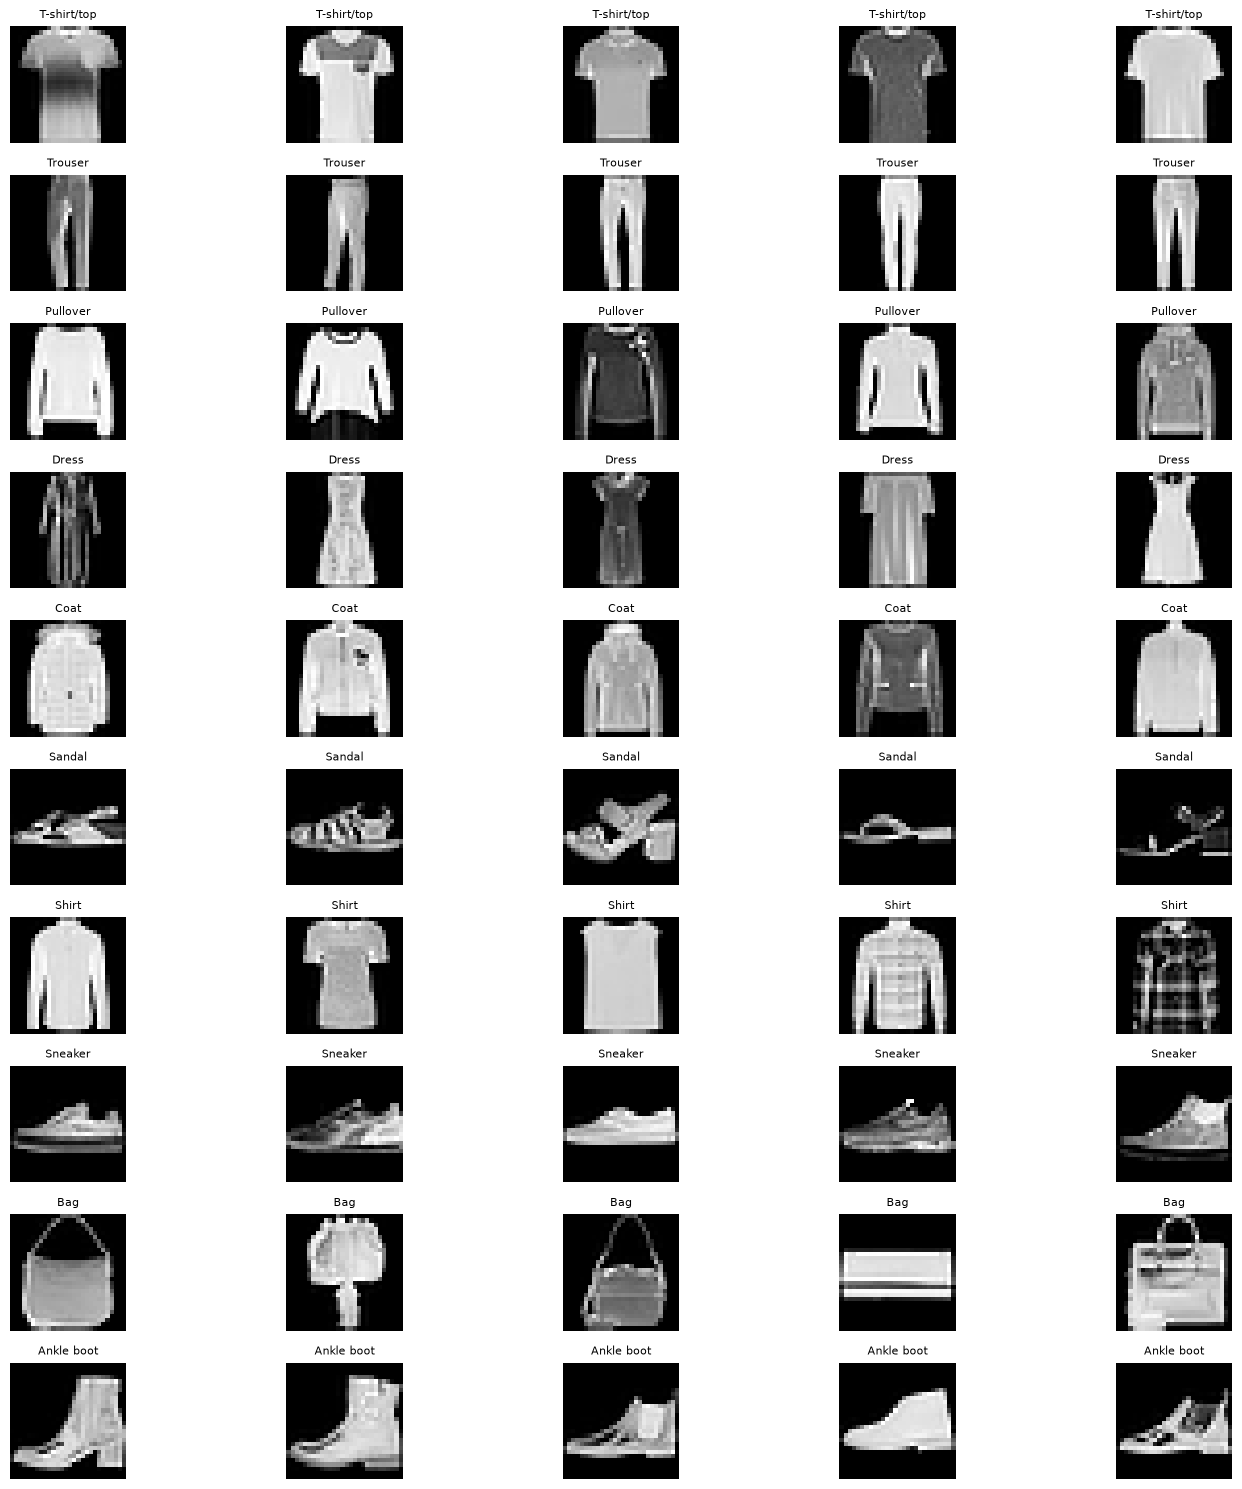

In [6]:
fig, axes = plt.subplots(10, 5, figsize=(15, 15))

for i in range(10):  # For each class
    # Find all images of this class
    class_samples = X[y == i]
    # Select 5 random images
    random_indices = np.random.choice(len(class_samples), 5, replace=False)

    for j, idx in enumerate(random_indices):
        axes[i, j].imshow(class_samples[idx].reshape(28,28), cmap='gray')
        axes[i, j].set_title(class_names[i], fontsize=8)
        axes[i, j].axis('off')


plt.tight_layout()
plt.show()

### 5. How does the frequency of class labels compare to one another? Illustrate your answer using a bar plot.


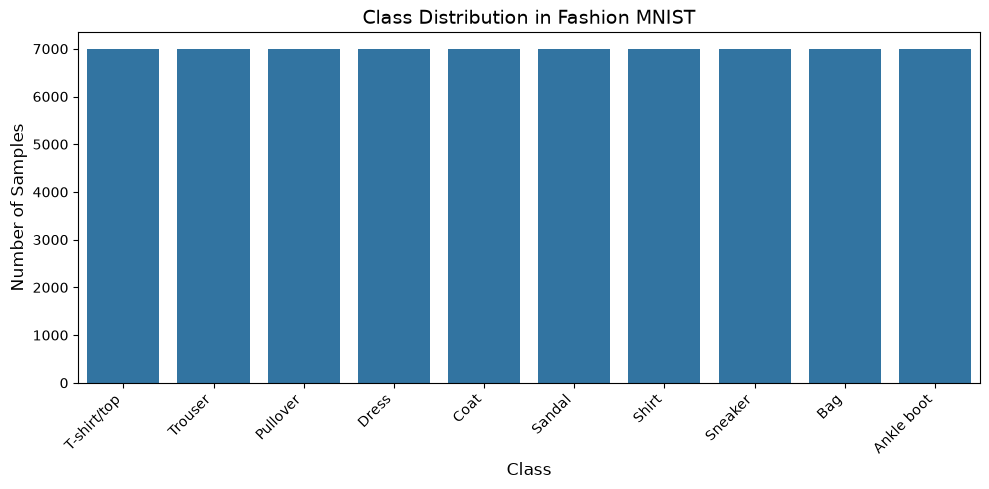

In [7]:
plt.figure(figsize=(10,5))
sns.countplot(x=y)
plt.title("Class Distribution in Fashion MNIST", fontsize=14)
plt.xlabel("Class", fontsize=12)
plt.ylabel("Number of Samples", fontsize=12)
plt.xticks(ticks=range(10), labels=class_names, rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Answer:** the classes are perfectly balanced: every one of the 10 classes has exactly 7,000 samples (70,000 / 10). Because of this, accuracy is a meaningful metric, and no resampling or class weighting is needed. The splits below are stratified, so each split keeps the same balance.

### 6. Randomly sample 100 data items from each class, and perform the following tasks on this subset of the dataset:

#### (a) Utilize t-SNE (t-distributed Stochastic Neighbor Embedding) to reduce the dimensionality of the dataset to three dimensions.

In [8]:
print("Sampling 100 items from each class...")
sampled_X, sampled_y = [], []
for i in range(10):
    idx = np.where(y == i)[0]
    chosen = np.random.choice(idx, 100, replace=False)
    sampled_X.append(X[chosen])
    sampled_y.extend([i]*100)
sampled_X = np.vstack(sampled_X)
sampled_y = np.array(sampled_y)

print(f"Number of selected samples: {sampled_X.shape[0]}")

# Run t-SNE
print("Running t-SNE (about 1 minute)...")
tsne = TSNE(n_components=3, random_state=42, perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(sampled_X)
print("t-SNE completed!\n")
print("Shape of the reduced dataset:", X_tsne.shape)

Sampling 100 items from each class...
Number of selected samples: 1000
Running t-SNE (about 1 minute)...
t-SNE completed!

Shape of the reduced dataset: (1000, 3)


#### (b) Visualize the resulting data in a 3D scatter plot, using distinct colors to differentiate between classes.

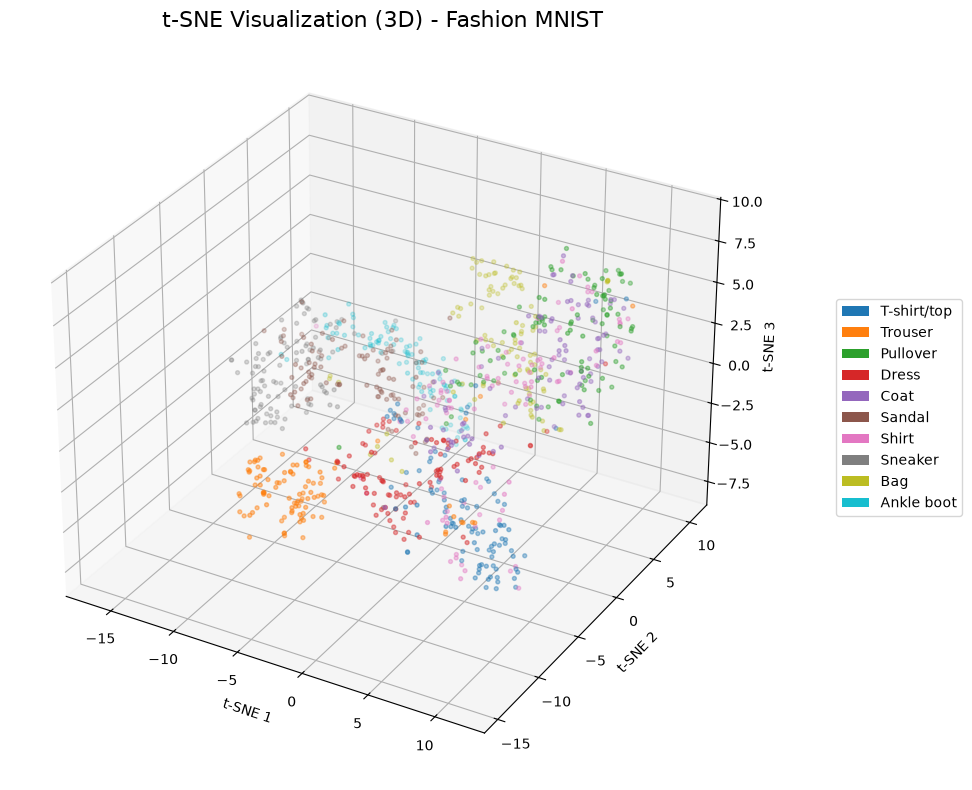

In [9]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot points with different colors
scatter = ax.scatter(X_tsne[:,0], X_tsne[:,1], X_tsne[:,2],
                     c=sampled_y, cmap='tab10', s=8, alpha=0.7)

ax.set_title("t-SNE Visualization (3D) - Fashion MNIST", fontsize=16)
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.set_zlabel("t-SNE 3")

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=plt.cm.tab10(i), label=class_names[i])
                   for i in range(10)]
ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.1, 0.5))

plt.tight_layout()
plt.show()

#### (c) Discuss the separability of the classes based on the visualization.

**Observations from the 3D t-SNE plot** (exact positions change with the sampling seed, but the overall pattern is stable):

**Well separated / compact classes**
- **Trouser** forms a compact group, and its nearest neighbour is **Dress**.
- The **footwear classes (Sandal, Sneaker, Ankle boot)** form a region that is clearly away from the clothing classes. Inside that region they are adjacent to each other, with some mixing (for example, Sneaker and Ankle boot).
- **Bag** is clearly away from the clothing classes, but it tends to be spread out in several sub-groups, which is consistent with the variety of bag shapes.

**Classes with strong overlap**
- **T-shirt/top, Shirt, Pullover and Coat** are heavily intermixed. **Shirt** is the most mixed class, since it sits in the middle of the other upper-body garments.
- **Dress** lies between Trouser and the T-shirt/Coat region and partially overlaps with them.

**Conclusion**
The data is easy to separate between *categories* (footwear, bags, trousers, tops), but hard to separate *within* the upper-body garment group. A KNN classifier should therefore do very well on the first group and make most of its errors among T-shirt/top, Shirt, Pullover and Coat. The confusion matrix computed later confirms this.

 (d) Considering the use of KNN for classification in this assignment, what specific property of t-SNE enables it to effectively highlight class separability in the visualization created in question 6c?
Please provide an explanation and reference a relevant textbook or academic paper that discusses this property

**Key property: t-SNE preserves local neighbourhood structure.**

t-SNE turns pairwise distances in the original 784-dimensional space into probabilities that point *j* is a neighbour of point *i* (a Gaussian kernel whose width is controlled by the perplexity). It then looks for a low-dimensional embedding whose neighbour probabilities (computed with a Student-t kernel) match the original ones, by minimising the Kullback-Leibler divergence. This divergence penalises heavily when points that are neighbours in the original space end up *far apart* in the embedding, so nearby points stay nearby.

**Why this matters for KNN:**
KNN classifies a sample using the labels of its nearest neighbours, so it relies on exactly the local structure that t-SNE preserves.
- If points of the same class form a compact group in the t-SNE map, their neighbourhoods in the original space are mostly of a single class, so KNN is expected to work well there (for example, Trouser and the footwear classes).
- If classes overlap in the map (for example, Shirt vs. T-shirt/top), many neighbourhoods contain mixed labels, so KNN is expected to make errors there.

**Caveat:** t-SNE does *not* preserve global structure. Distances between clusters and cluster sizes in the plot are not meaningful, so the plot should be read as "local neighbourhoods are (or are not) class-pure", and not as a measure of how far apart the classes are in the original space.

**References**
- van der Maaten, L., & Hinton, G. (2008). Visualizing data using t-SNE. *Journal of Machine Learning Research, 9*, 2579-2605.
- Wattenberg, M., Viegas, F., & Johnson, I. (2016). How to Use t-SNE Effectively. *Distill*.

# Preprocessing


### Data Splitting

In [10]:
# Split data into 70-15-15
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(f"Training: {X_train.shape[0]} samples")
print(f"Validation: {X_val.shape[0]} samples")
print(f"Test: {X_test.shape[0]} samples")

Training: 49000 samples
Validation: 10500 samples
Test: 10500 samples


### Preprocessing function

In [11]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, roc_auc_score)
from sklearn.preprocessing import MinMaxScaler, StandardScaler

def preprocess(train, val, variance_ratio=0.90, scaler_type='minmax'):
    if scaler_type == 'minmax':
        scaler = MinMaxScaler()
        train_scaled = scaler.fit_transform(train)
        val_scaled   = scaler.transform(val)
    elif scaler_type == 'standard':
        scaler = StandardScaler()
        train_scaled = scaler.fit_transform(train)
        val_scaled   = scaler.transform(val)
    else:
        train_scaled = train.copy()
        val_scaled   = val.copy()

    pca = PCA(n_components=variance_ratio, random_state=42)
    train_pca = pca.fit_transform(train_scaled)
    val_pca   = pca.transform(val_scaled)
    return train_pca, val_pca, pca.n_components_

### implement the K-Nearest Neighbors (KNN) algorithm from scratch <br>
The implementation includes:

- **Distance calculation** using Euclidean distance
- **K-nearest neighbor search** using sorting
- **Weighted voting** based on inverse distance

In [12]:
def knn_predictor(train_data, train_labels, test_data, k=5, metric='euclidean',
                  weighted=True, eps=1e-5, return_scores=False):

    classes = np.unique(train_labels)

    def vote(neighbor_list):
        score_board = {c: 0.0 for c in classes}
        if weighted:
            for lbl, dist in neighbor_list:
                score_board[lbl] += 1.0 / (dist + eps)
        else:
            for lbl, _ in neighbor_list:
                score_board[lbl] += 1.0

        total = sum(score_board.values()) + 1e-12
        probs = np.array([score_board[c] / total for c in classes])
        pred  = classes[np.argmax(probs)]
        return pred, probs

    preds, scores = [], []
    for sample in test_data:
        if metric == 'euclidean':
            dists = np.sqrt(np.sum((train_data - sample)**2, axis=1))
        else:
            dists = np.sum(np.abs(train_data - sample), axis=1)

        idxs = np.argsort(dists)[:k]
        neighbors = [(train_labels[i], dists[i]) for i in idxs]
        pred, probs = vote(neighbors)
        preds.append(pred)
        scores.append(probs)

    preds = np.array(preds)
    if return_scores:
        return preds, np.array(scores)
    return preds

In [13]:
def print_per_class_metrics(y_true, y_pred, y_scores, title=""):
    precision = precision_score(y_true, y_pred, average=None, zero_division=0)
    recall    = recall_score(y_true, y_pred, average=None, zero_division=0)
    f1        = f1_score(y_true, y_pred, average=None, zero_division=0)
    auc       = roc_auc_score(y_true, y_scores, multi_class='ovr', average=None)

    df = pd.DataFrame({
        'Class'     : class_names,
        'Precision' : np.round(precision, 4),
        'Recall'    : np.round(recall, 4),
        'F1-Score'  : np.round(f1, 4),
        'AUC'       : np.round(auc, 4)
    })

    print(f"\n{title}")
    print(df.to_string(index=False))
    print("-" * 65)
    print(f"Macro Avg → Precision: {precision.mean():.4f} | "
          f"Recall: {recall.mean():.4f} | F1: {f1.mean():.4f} | AUC: {auc.mean():.4f}")
    print(f"Accuracy  → {accuracy_score(y_true, y_pred):.4f}")
    print("=" * 65)
    return df

In [14]:
import time
from sklearn.model_selection import StratifiedShuffleSplit

In [15]:
USE_SUBSAMPLE = True
if USE_SUBSAMPLE:
    sss = StratifiedShuffleSplit(n_splits=1, train_size=10000, random_state=42)
    for idx, _ in sss.split(X_train, y_train):
        X_tr_sub = X_train[idx]
        y_tr_sub = y_train[idx]
    print(f"Using subsample: {len(y_tr_sub)} samples\n")
else:
    X_tr_sub, y_tr_sub = X_train, y_train

configs = [

    ('minmax',   0.85, 5, 'euclidean', True),
    ('minmax',   0.90, 5, 'euclidean', True),
    ('minmax',   0.90, 7, 'euclidean', True),
    ('minmax',   0.90, 7, 'manhattan', True),
    ('minmax',   0.90, 9, 'euclidean', True),
    ('minmax',   0.95, 7, 'euclidean', True),
    ('standard', 0.90, 7, 'euclidean', True),
    ('standard', 0.90, 7, 'manhattan', True),
    ('minmax',   0.90, 7, 'euclidean', False),
]

results = []

for i, (scaler_type, var, k, metric, weighted) in enumerate(configs, 1):
    print(f"\n[{i}/{len(configs)}] scaler={scaler_type} | var={var} | k={k} | "
          f"metric={metric} | weighted={weighted}")

    start = time.time()

    X_tr, X_va, n_comp = preprocess(X_tr_sub, X_val, variance_ratio=var, scaler_type=scaler_type)

    preds, scores = knn_predictor(
        X_tr, y_tr_sub, X_va,
        k=k, metric=metric, weighted=weighted, return_scores=True
    )

    acc       = accuracy_score(y_val, preds)
    prec      = precision_score(y_val, preds, average=None, zero_division=0)
    rec       = recall_score(y_val, preds, average=None, zero_division=0)
    f1        = f1_score(y_val, preds, average=None, zero_division=0)
    auc_cls   = roc_auc_score(y_val, scores, multi_class='ovr', average=None)
    auc_macro = float(auc_cls.mean())

    elapsed = time.time() - start


    title = (f"Config {i}: scaler={scaler_type}, var={var}, k={k}, "
             f"metric={metric}, weighted={weighted}")
    print_per_class_metrics(y_val, preds, scores, title=title)

    results.append({
        'scaler'      : scaler_type,
        'pca_var'     : var,
        'n_neighbors' : k,
        'metric'      : metric,
        'weighted'    : weighted,
        'n_components': n_comp,
        'accuracy'    : round(acc, 4),
        'macro_f1'    : round(float(f1.mean()), 4),
        'macro_auc'   : round(auc_macro, 4),
        'time_sec'    : round(elapsed, 1),
        'precision'   : np.round(prec, 4).tolist(),
        'recall'      : np.round(rec, 4).tolist(),
        'f1_score'    : np.round(f1, 4).tolist(),
        'auc'         : np.round(auc_cls, 4).tolist()
    })

Using subsample: 10000 samples


[1/9] scaler=minmax | var=0.85 | k=5 | metric=euclidean | weighted=True

Config 1: scaler=minmax, var=0.85, k=5, metric=euclidean, weighted=True
      Class  Precision  Recall  F1-Score    AUC
T-shirt/top     0.7706  0.8381    0.8029 0.9649
    Trouser     0.9832  0.9448    0.9636 0.9839
   Pullover     0.7405  0.7067    0.7232 0.9424
      Dress     0.8551  0.8657    0.8604 0.9767
       Coat     0.6992  0.7705    0.7331 0.9517
     Sandal     0.9630  0.8667    0.9123 0.9797
      Shirt     0.6352  0.5705    0.6011 0.8960
    Sneaker     0.8962  0.9048    0.9005 0.9832
        Bag     0.9565  0.9419    0.9491 0.9867
 Ankle boot     0.8821  0.9619    0.9203 0.9909
-----------------------------------------------------------------
Macro Avg → Precision: 0.8382 | Recall: 0.8371 | F1: 0.8366 | AUC: 0.9656
Accuracy  → 0.8371

[2/9] scaler=minmax | var=0.9 | k=5 | metric=euclidean | weighted=True

Config 2: scaler=minmax, var=0.9, k=5, metric=euclidean, weigh

In [16]:
df = pd.DataFrame(results).sort_values('accuracy', ascending=False)

print("\n" + "=" * 65)
print("SUMMARY - All Configurations (sorted by Accuracy)")
print("=" * 65)
print(df[['scaler', 'pca_var', 'n_neighbors', 'metric', 'weighted',
          'n_components', 'accuracy', 'macro_f1', 'macro_auc', 'time_sec']]
      .to_string(index=False))

best = df.iloc[0]
print("\n" + "=" * 65)
print("BEST CONFIGURATION")
print("=" * 65)
print(f"scaler       : {best['scaler']}")
print(f"pca_var      : {best['pca_var']}")
print(f"n_neighbors  : {best['n_neighbors']}")
print(f"metric       : {best['metric']}")
print(f"weighted     : {best['weighted']}")
print(f"n_components : {best['n_components']}")
print(f"Accuracy     : {best['accuracy']}")
print(f"Macro F1     : {best['macro_f1']}")
print(f"Macro AUC    : {best['macro_auc']}")


SUMMARY - All Configurations (sorted by Accuracy)
  scaler  pca_var  n_neighbors    metric  weighted  n_components  accuracy  macro_f1  macro_auc  time_sec
standard     0.90            7 manhattan      True           130    0.8420    0.8423     0.9737      49.3
standard     0.90            7 euclidean      True           130    0.8413    0.8414     0.9718      47.7
  minmax     0.90            7 manhattan      True            83    0.8412    0.8411     0.9736      32.3
  minmax     0.90            5 euclidean      True            83    0.8406    0.8401     0.9668      42.1
  minmax     0.90            7 euclidean      True            83    0.8392    0.8386     0.9724      32.7
  minmax     0.95            7 euclidean      True           183    0.8374    0.8373     0.9717      78.9
  minmax     0.90            7 euclidean     False            83    0.8373    0.8360     0.9717      30.5
  minmax     0.85            5 euclidean      True            43    0.8371    0.8366     0.9656      

**Note on the comparison:** all nine configurations land within about 0.5 percentage points of each other (accuracy between 0.8367 and 0.8420), so the "best" configuration is only marginally better than the rest, and the ranking could change with a different random subsample. The comparison was run on a 10,000-sample subset of the training data for speed, while the final model below is trained on the full training set. This is also why the number of PCA components differs (130 on the subset vs. about 137 on the full training set for the same 90% variance target).

PCA dimensions: 137


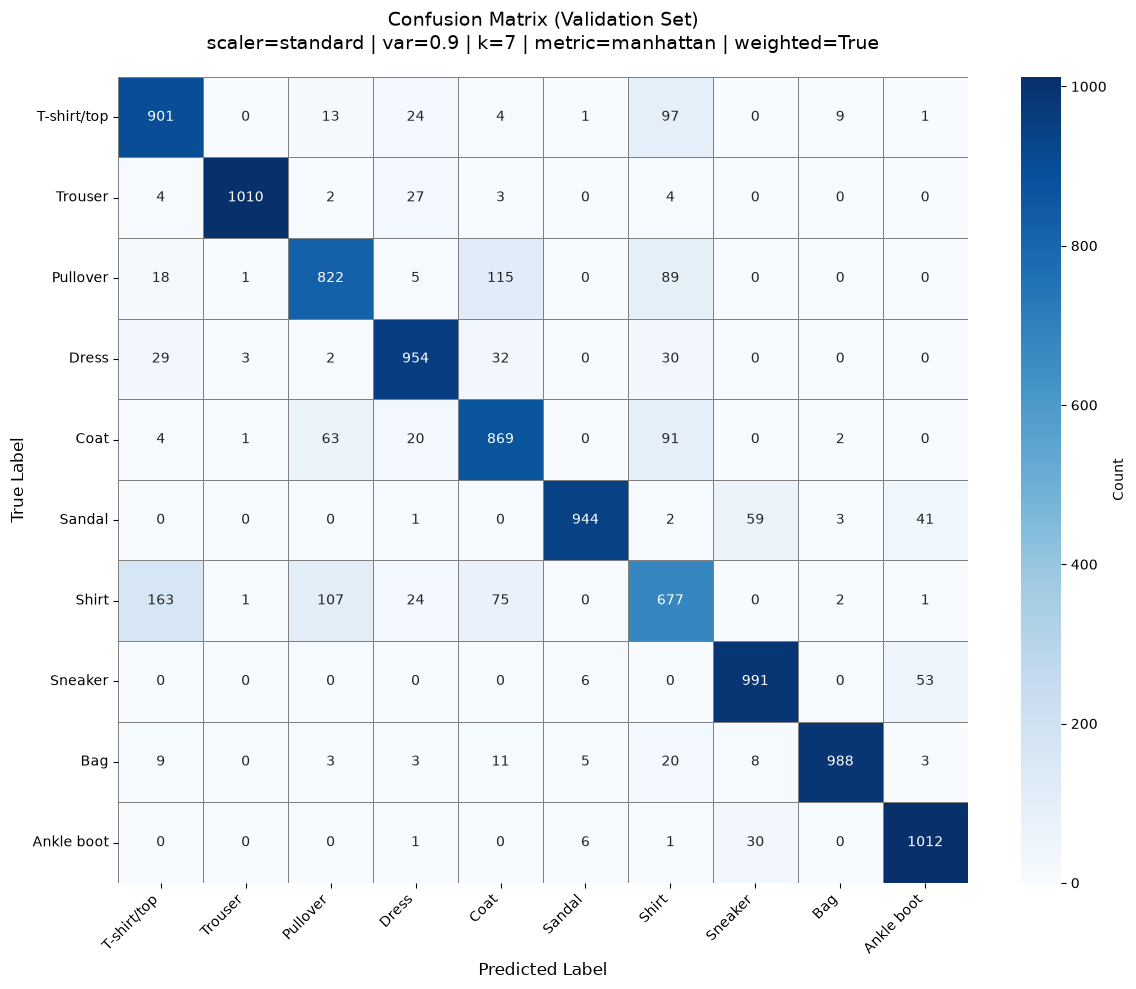

In [17]:
# Best configuration, taken directly from the comparison table above
best_scaler   = best['scaler']
best_var      = float(best['pca_var'])
best_k        = int(best['n_neighbors'])
best_metric   = best['metric']
best_weighted = bool(best['weighted'])


def plot_confusion_matrix(y_true, y_pred, split_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                linewidths=0.5, linecolor='gray', cbar_kws={'label': 'Count'})
    plt.title(f'Confusion Matrix ({split_name})\n'
              f'scaler={best_scaler} | var={best_var} | k={best_k} | '
              f'metric={best_metric} | weighted={best_weighted}',
              fontsize=14, pad=20)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.ylabel('True Label', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


# Retrain with the best configuration on the FULL training set
X_tr, X_va, n_comp = preprocess(X_train, X_val,
                                variance_ratio=best_var,
                                scaler_type=best_scaler)
print(f"PCA dimensions: {n_comp}")

# Keep the scores: they are needed for the ROC curves of THIS model
val_preds, val_scores = knn_predictor(
    X_tr, y_train, X_va,
    k=best_k, metric=best_metric, weighted=best_weighted,
    return_scores=True
)

plot_confusion_matrix(y_val, val_preds, 'Validation Set')

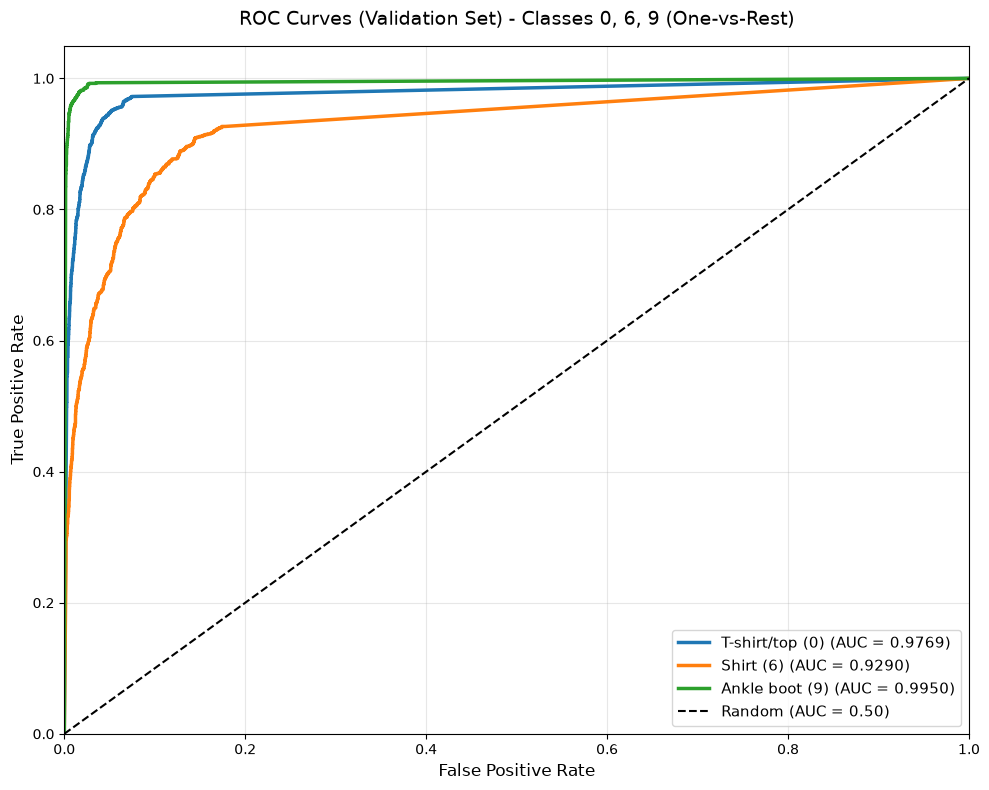

In [18]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

target_classes = [0, 6, 9]
class_names_map = {
    0: 'T-shirt/top (0)',
    6: 'Shirt (6)',
    9: 'Ankle boot (9)'
}

# One-vs-Rest binarization of the validation labels
y_val_bin = label_binarize(y_val, classes=np.arange(10))

plt.figure(figsize=(10, 8))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for color, cls in zip(colors, target_classes):
    # val_scores comes from the SAME best model used for the confusion matrix
    fpr, tpr, _ = roc_curve(y_val_bin[:, cls], val_scores[:, cls])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2.5,
             label=f'{class_names_map[cls]} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves (Validation Set) - Classes 0, 6, 9 (One-vs-Rest)', fontsize=14, pad=15)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Final evaluation on the test set

The test set has not been used so far (neither for training nor for choosing hyperparameters). It is evaluated **once**, using the best configuration found on the validation set. For the final model, the training and validation sets are merged, and the scaler, PCA and KNN are fitted on the merged data.

In [19]:
# Merge train + validation, then fit scaler/PCA/KNN on the merged data only
X_trainval = np.vstack([X_train, X_val])
y_trainval = np.concatenate([y_train, y_val])

X_trv, X_te, n_comp_final = preprocess(X_trainval, X_test,
                                       variance_ratio=best_var,
                                       scaler_type=best_scaler)
print(f"PCA dimensions: {n_comp_final}")

test_preds, test_scores = knn_predictor(
    X_trv, y_trainval, X_te,
    k=best_k, metric=best_metric, weighted=best_weighted,
    return_scores=True
)

df_test = print_per_class_metrics(y_test, test_preds, test_scores,
                                  title="Final evaluation on the TEST set")

PCA dimensions: 137

Final evaluation on the TEST set
      Class  Precision  Recall  F1-Score    AUC
T-shirt/top     0.8143  0.8352    0.8246 0.9776
    Trouser     0.9932  0.9714    0.9822 0.9942
   Pullover     0.7966  0.7686    0.7824 0.9616
      Dress     0.8895  0.9048    0.8971 0.9867
       Coat     0.7600  0.7990    0.7790 0.9681
     Sandal     0.9842  0.8914    0.9355 0.9912
      Shirt     0.6631  0.6524    0.6577 0.9288
    Sneaker     0.9071  0.9486    0.9274 0.9951
        Bag     0.9716  0.9457    0.9585 0.9917
 Ankle boot     0.9160  0.9657    0.9402 0.9956
-----------------------------------------------------------------
Macro Avg → Precision: 0.8696 | Recall: 0.8683 | F1: 0.8685 | AUC: 0.9791
Accuracy  → 0.8683


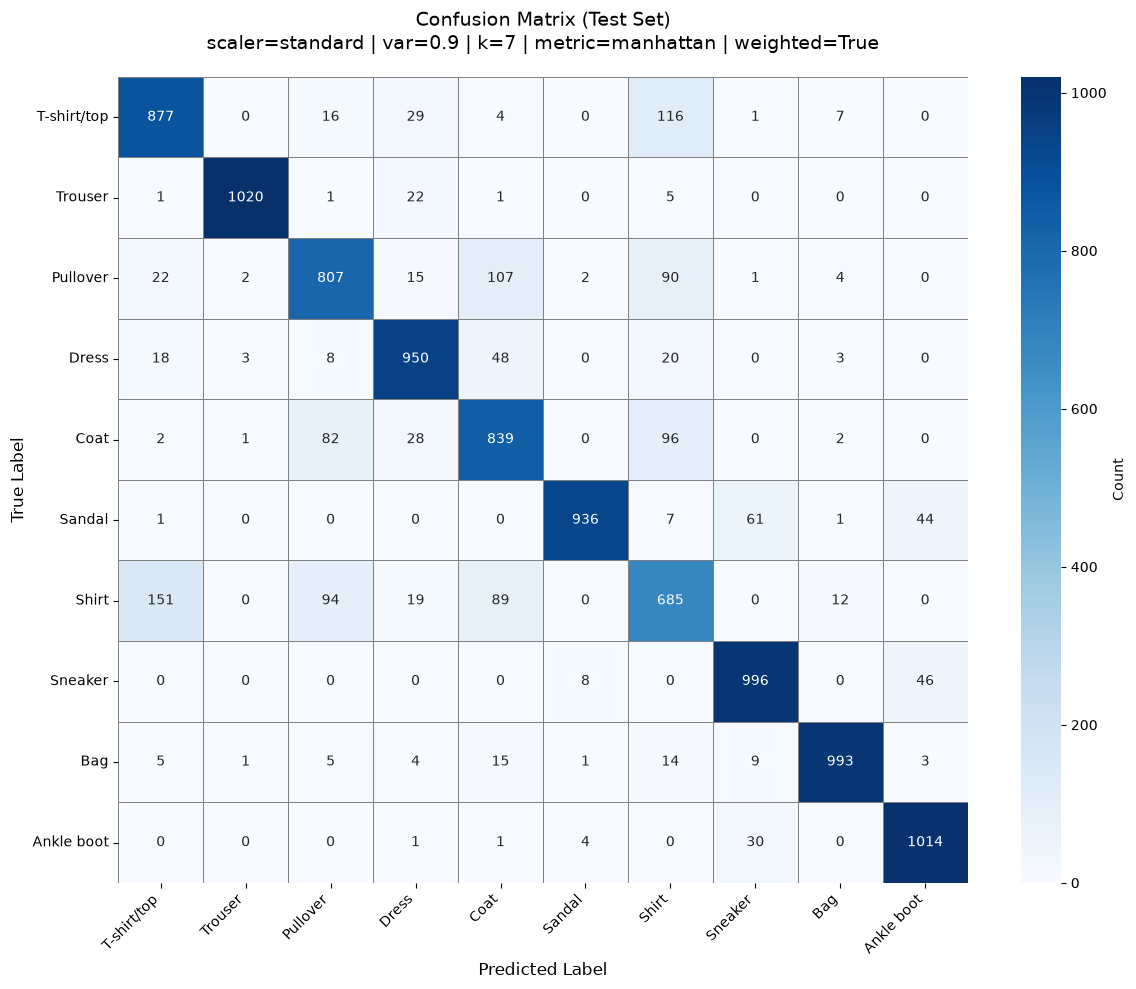

In [20]:
plot_confusion_matrix(y_test, test_preds, 'Test Set')

### Conclusion

Compare the test accuracy above with the validation accuracy of the same configuration. If the two are close, the hyperparameter search did not overfit the validation set. As seen in the t-SNE plot, the confusion matrices show that most errors happen among the visually similar upper-body garments (T-shirt/top, Shirt, Pullover, Coat), while footwear, bags and trousers are classified almost perfectly.